# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

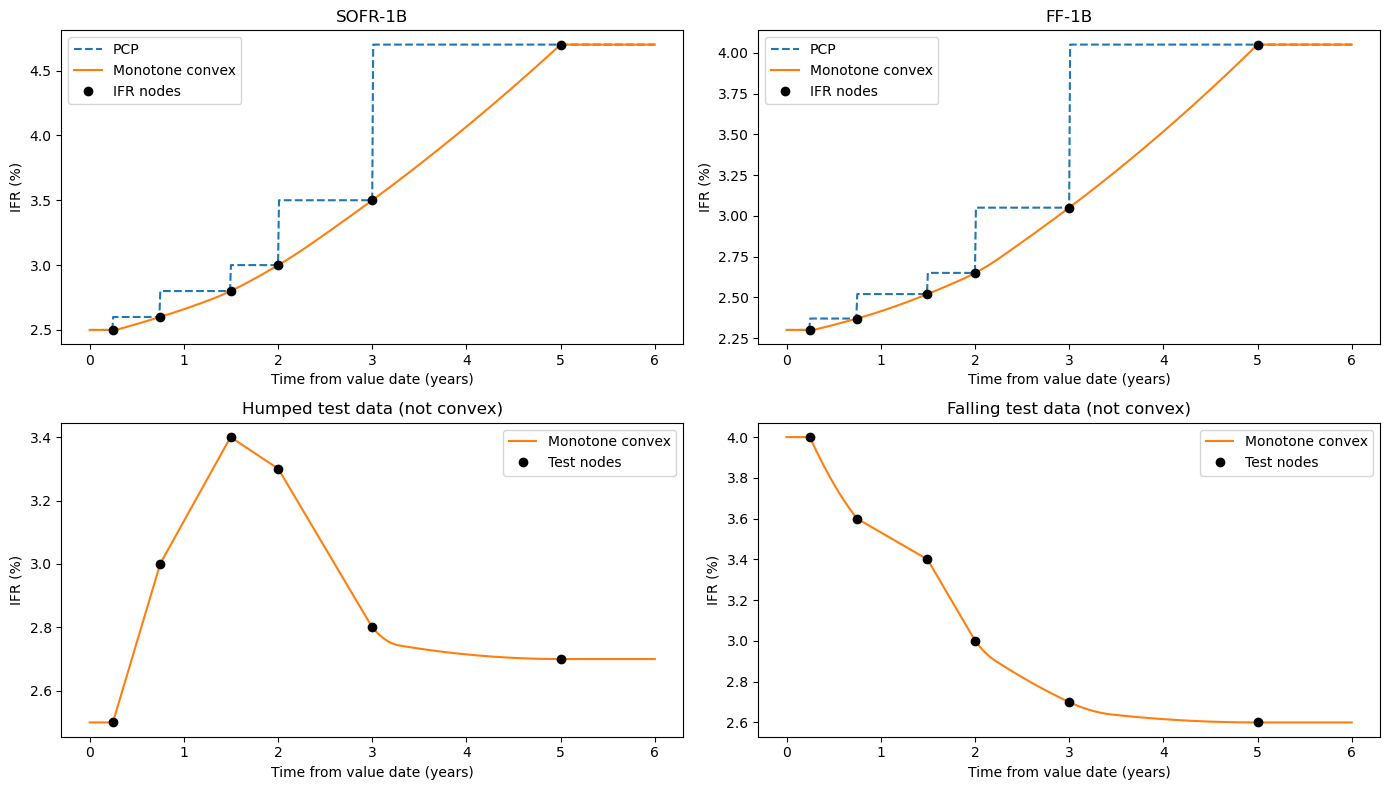

SOFR-1B            max node error 0.0e+00 | monotone and convex in every interval: True | largest kink 1.7e-08
FF-1B              max node error 0.0e+00 | monotone and convex in every interval: True | largest kink 9.3e-09
Humped test data   max node error 0.0e+00 | monotone and convex in every interval: True | largest kink 1.0e-02
Falling test data  max node error 0.0e+00 | monotone and convex in every interval: True | largest kink 1.0e-02


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from fixedincomelib.utilities.numerics import (
    InterpolatorFactory, InterpMethod, ExtrapMethod,
)

targets = ["SOFR-1B", "FF-1B"]
methods = {
    "PIECEWISE_CONSTANT_LEFT_CONTINUOUS": "PCP",
    "MONOTONE_CONVEX": "Monotone convex",
}
curves = {}
for method in methods:
    build_methods = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {
            **inputs,
            "INTERPOLATION METHOD": method,
            "EXTRAPOLATION METHOD": "FLAT",
        }) for kind, inputs in curve_inputs
    ])
    model = qfCreateModel("2026-01-02", "YIELD_CURVE", data_collection, build_methods)
    for target in targets:
        component = model.retrieve_model_component(target)
        curves[target, method] = component.state_data_interpolator

# Test data on the same nodes that cannot be convex at every node.
nodes = curves["SOFR-1B", "MONOTONE_CONVEX"].axis1
test_data = {
    "Humped test data": [0.025, 0.030, 0.034, 0.033, 0.028, 0.027],
    "Falling test data": [0.040, 0.036, 0.034, 0.030, 0.027, 0.026],
}
test_curves = {
    name: InterpolatorFactory.create_1d_interpolator(
        nodes, values, InterpMethod.MONOTONE_CONVEX, ExtrapMethod.FLAT)
    for name, values in test_data.items()
}

times = np.linspace(0.0, 6.0, 601)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.ravel()
for ax, target in zip(axes, targets):
    for method, label in methods.items():
        curve = curves[target, method]
        style = "--" if label == "PCP" else "-"
        ax.plot(times, [100 * curve.interpolate(t) for t in times], style, label=label)
    ax.plot(curve.axis1, 100 * curve.values, "o", color="black", label="IFR nodes")
    ax.set_title(target)
for ax, (name, curve) in zip(axes[2:], test_curves.items()):
    ax.plot(times, [100 * curve.interpolate(t) for t in times], color="C1",
            label="Monotone convex")
    ax.plot(curve.axis1, 100 * curve.values, "o", color="black", label="Test nodes")
    ax.set_title(name + " (not convex)")
for ax in axes:
    ax.set(xlabel="Time from value date (years)", ylabel="IFR (%)")
    ax.legend()
plt.tight_layout()
plt.show()


def check_shape(curve, points=400, eps=1e-6):
    x, y = curve.axis1, curve.values
    node_error = max(abs(curve.interpolate(t) - v) for t, v in zip(x, y))
    shape_ok = True
    for a, b in zip(x[:-1], x[1:]):
        dv = np.diff([curve.interpolate(t) for t in np.linspace(a, b, points)])
        monotone = (dv >= -1e-12).all() or (dv <= 1e-12).all()
        convex = (np.diff(dv) >= -1e-12).all()
        shape_ok = shape_ok and monotone and convex
    # Slope jump at each node except the last (0 means smooth there).
    kinks = [abs(curve.interpolate(t + eps) - 2 * curve.interpolate(t)
                 + curve.interpolate(t - eps)) / eps for t in x[:-1]]
    return node_error, shape_ok, max(kinks)


all_curves = {"SOFR-1B": curves["SOFR-1B", "MONOTONE_CONVEX"],
              "FF-1B": curves["FF-1B", "MONOTONE_CONVEX"], **test_curves}
for name, curve in all_curves.items():
    node_error, shape_ok, kink = check_shape(curve)
    print(f"{name:18s} max node error {node_error:.1e} | "
          f"monotone and convex in every interval: {shape_ok} | "
          f"largest kink {kink:.1e}")

### Method: shape-preserving piecewise quadratic

Hagan and West start from discrete forwards (interval averages) and, when a plain quadratic
would not be monotone, split the interval at a break point into a flat part and a quadratic or
into two quadratics. Here the IFR value is given *at* each node and the curve must pass through
it, so the break-point idea is kept but the pieces are built from node slopes. Let
$h_i = t_{i+1} - t_i$ and $d_i = (y_{i+1} - y_i)/h_i$.

1. **Node slopes.** $m_i$ is the slope of the parabola through a node and its two neighbours,
   so it lies between $d_{i-1}$ and $d_i$; $m_i = 0$ if the data turns around there. At the
   first node the slope is 0 when the curve rises, so it joins the flat extrapolation smoothly;
   otherwise $m_0 = 2d_0 - m_1$. The last node is treated the same way (slope 0 when the curve
   falls).
2. **One interval.** The slope moves linearly from $s_0$ (left node) to $d_i$ at a break point,
   then to $s_1$ (right node). The break point $t_i + h_i (s_1 - d_i)/(s_1 - s_0)$ makes the
   average slope $d_i$, so the curve ends exactly at $y_{i+1}$.
3. **Monotone and convex.** With $s_0 \le d_i \le s_1$ the slope only rises (convex), and with
   $s_0, s_1$ of the same sign as $d_i$ it never changes sign (monotone). For convex data this
   holds automatically and the slopes match at every node, so the curve is smooth too.

**Data that cannot satisfy everything.** If the data is not convex at a node
($d_{i-1} > d_i$), no curve can be convex on both sides and smooth there: convexity needs a
slope of at least $d_{i-1}$ just before the node and at most $d_i$ just after it. Continuity,
the node values, and monotonicity and convexity in each interval are kept, and smoothness is
given up: the end slopes are clipped to $d_{i-1}$ and $d_i$, so the kink is the smallest
possible, $d_{i-1} - d_i$. An interval touching such a node then becomes a straight line (its
slope cannot rise and still average $d_i$), so a neighbouring node can also get a small kink.
Outside the nodes the curve is flat, so the one-node funding curve is constant.

**Positivity and locality.** Within each interval the curve stays between its two node values,
so it is positive whenever the inputs are, as Hagan and West require to avoid negative forwards.
Moving one node changes the curve on at most two intervals on each side of it, so the method
and its hedges stay local.

**Integration.** Every piece is a quadratic, so $\int_0^T f(t)\,dt$ for the discount factors
is exact.

**What the plots show.** SOFR and FF are increasing and convex, so the monotone convex curve is
smooth (largest kink about $10^{-8}$, the finite-difference error), increasing and convex
through every node, while PCP jumps to the next node's value. The humped test data rises more
and more slowly up to 1.5Y and falls faster and faster to 3Y; the falling test data is not
convex at 1.5Y. In both, the intervals next to a non-convex node become straight lines with
kinks, and the others stay curved. A falling curve must start with a negative slope, so it also
has a kink where it meets the flat part before the first node. The printed checks confirm
every curve passes through its nodes and is monotone and convex in each interval.

In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3267.1271708331933
Student minus PCP: 358.84053159522955


In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513070154


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12852.785707786214
Student minus PCP: 6630.26819471606


In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7623.189411015825
Student minus PCP: -728.1594971661689


### PV comparison

| Product | PCP PV | Monotone convex PV | Difference |
|---|---:|---:|---:|
| FRA (receive fixed) | 2,908.29 | 3,267.13 | +358.84 |
| RFR swap (receive fixed) | 6,222.52 | 12,852.79 | +6,630.27 |
| Basis swap (receive SOFR + 10bp, pay FF) | 8,351.35 | 7,623.19 | -728.16 |

PCP is left-continuous: between two nodes it uses the value of the right node. Both curves are
increasing, so PCP puts every forward at the top of its interval. The monotone convex curve
equals PCP at the nodes but moves smoothly between them, so it is lower in between. Projected
forwards are therefore lower with the monotone convex interpolator.

- **FRA and RFR swap.** Both receive fixed and pay floating, so lower forwards make the floating
  leg cheaper and the PV goes up. The swap gap is much larger because it is longer and its last
  year runs past the 3Y node, where PCP already uses 4.7%. Over that year the average SOFR
  forward is 3.80% with PCP and 3.37% with monotone convex.
- **Basis swap.** What matters is the SOFR minus FF gap, which widens with maturity (20bp at the
  first node, 45bp at 3Y). PCP uses the right node's gap over each whole interval, so it uses
  the largest gap. Over the life of the swap the average gap is 33.4bp with PCP and 29.5bp with
  monotone convex, so the received SOFR leg is worth less and the PV goes down.

Discounting also changes slightly, because the funding curve is SOFR plus a spread, but the
forwards are the main effect.